# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [2]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 streamlit==1.43.2 PyGithub==2.6.1 -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> pandas

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [2]:
!pip install PyGithub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyGithub]


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [3]:
# For data manipulation
# for data manipulation
import pandas as pd
import numpy as np

import sklearn
import xgboost
import matplotlib.pyplot as plt
import seaborn as sns

# for data preprocessing and pipeline creation
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn import metrics
from sklearn.pipeline import Pipeline # Import Pipeline

# for model training, tuning, and evaluation (regression metrics)
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# for model serialization
import joblib

# for creating a folder
import os

# for GitHub authentication to push files
from github import Github

In [4]:
# Set scikit-learn's display mode to 'diagram' for better visualization of pipelines and estimators
sklearn.set_config(display='diagram')

# Loading the dataset

Place `SuperKart.csv` in the notebook working directory, or change `DATA_PATH` in the next cell.

In [10]:
# Load the SuperKart dataset. Upload SuperKart.csv to the notebook's working directory first.

SuperKart_data = pd.read_csv("SuperKart.csv",low_memory=False)
# DATA_PATH = "SuperKart.csv"

display(dataset.head())

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [11]:
# Create a copy of the dataframe
dataset = SuperKart_data.copy()

# **Data Overview**

In [12]:
# Display the first five rows of the dataset
dataset.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [13]:
# checking shape of the data
print(f"There are {dataset.shape[0]} rows and {dataset.shape[1]} columns.")

There are 8763 rows and 12 columns.


In [14]:
# Display the column names of the dataset
dataset.columns

Index(['Product_Id', 'Product_Weight', 'Product_Sugar_Content',
       'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id',
       'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type',
       'Store_Type', 'Product_Store_Sales_Total'],
      dtype='object')

In [15]:
# checking column datatypes and number of non-null values
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


In [16]:
# checking for duplicate values
dataset.duplicated().sum()

np.int64(0)

In [25]:
# checking for missing values
dataset.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


In [26]:

# Define the target variable for the regression task
target = 'Product_Store_Sales_Total'

# List of numerical features in the dataset (excluding 'id' as it is an identifier)
numeric_features = [
    'Product_Weight',            # Product Weight
    'Product_Allocated_Area',    # Area allocated for the product
    'Product_MRP',               # Product MRP
    'Product_Store_Sales_Total'  # Total sales for ecah product by store

]

# List of categorical features in the dataset
categorical_features = [
    'Product_Id',             # Product ID
    'Product_Sugar_Content',   # Sugar Content for product
    'Product_Type',            # Product Type
    'Store_Id',                # Store ID
    'Store_Establishment_Year',# Year Store established
    'Store_Size',              # Store Size
    'Store_Location_City_Type',# Store Location
    'Store_Type'               # Store Type
]

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [27]:
# Generate summary statistics for numerical features
dataset[numeric_features].describe()

,Product_Weight,Product_Allocated_Area,Product_MRP,Product_Store_Sales_Total
count,8763.000000,8763.000000,8763.000000,8763.000000
mean,12.653792,0.068786,147.032539,3464.003640
std,2.217320,0.048204,30.694110,1065.630494
min,4.000000,0.004000,31.000000,33.000000
25%,11.150000,0.031000,126.160000,2761.715000
50%,12.660000,0.056000,146.740000,3452.340000
75%,14.180000,0.096000,167.585000,4145.165000
max,22.000000,0.298000,266.000000,8000.000000


In [30]:
# Generate summary statistics for categorical features
dataset[categorical_features].describe()

,Store_Establishment_Year
count,8763.000000
mean,2002.032751
std,8.388381
min,1987.000000
25%,1998.000000
50%,2009.000000
75%,2009.000000
max,2009.000000


In [31]:
 # Let's check the unique values for categorical variables

# list of all categorical variables
cat_col = dataset.select_dtypes(include="object").columns.tolist()

# printing the number of occurrences of each unique value in each categorical column
for column in cat_col:
    print(dataset[column].value_counts(normalize=True))
    print("-" * 50)

Product_Id
FD306     0.000114
FD6114    0.000114
FD7839    0.000114
FD5075    0.000114
FD8233    0.000114
            ...   
FD1387    0.000114
FD1231    0.000114
FD5276    0.000114
FD8553    0.000114
FD6027    0.000114
Name: proportion, Length: 8763, dtype: float64
--------------------------------------------------
Product_Sugar_Content
Low Sugar    0.557457
Regular      0.256875
No Sugar     0.173342
reg          0.012325
Name: proportion, dtype: float64
--------------------------------------------------
Product_Type
Fruits and Vegetables    0.142531
Snack Foods              0.131119
Frozen Foods             0.092548
Dairy                    0.090836
Household                0.084446
Baking Goods             0.081707
Canned                   0.077257
Health and Hygiene       0.071665
Meat                     0.070524
Soft Drinks              0.059226
Breads                   0.022823
Hard Drinks              0.021226
Others                   0.017232
Starchy Foods            0.016090

In [32]:
# Generate summary statistics for the target variable
dataset[target].describe()

,Product_Store_Sales_Total
count,8763.000000
mean,3464.003640
std,1065.630494
min,33.000000
25%,2761.715000
50%,3452.340000
75%,4145.165000
max,8000.000000


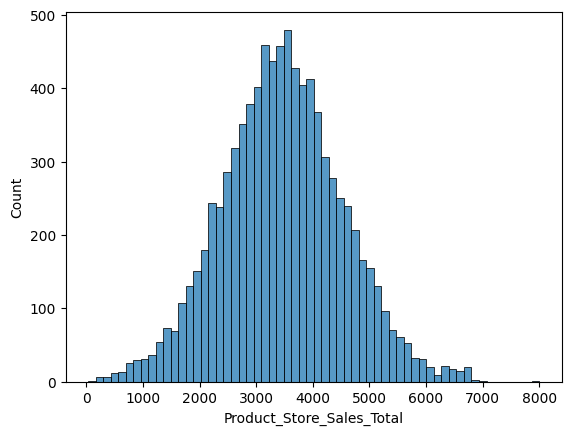

In [33]:
# Check the distribution of the target variable
sns.histplot(dataset[target]);

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


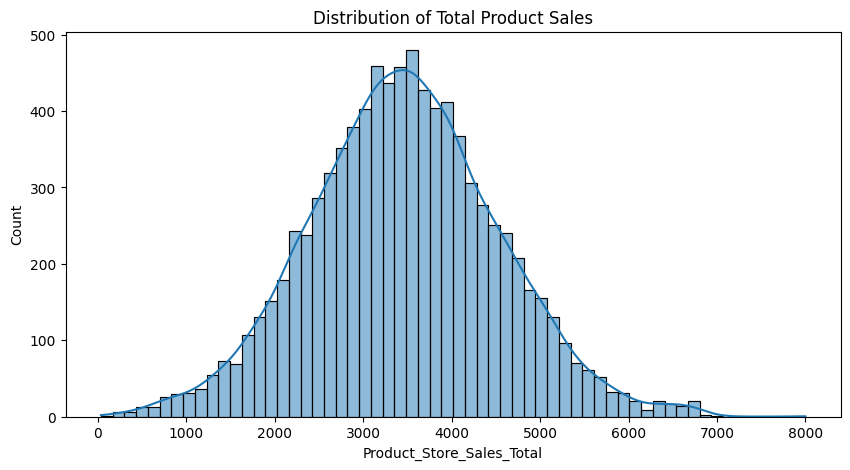

In [37]:
# Univariate overview: target distribution and numeric feature distributions
if target not in dataset.columns:
    raise KeyError(f"Expected target column {target!r}; available columns: {dataset.columns.tolist()}")

display(dataset.describe(include="all").T)
plt.figure(figsize=(10, 5))
sns.histplot(dataset[target].dropna(), kde=True)
plt.title("Distribution of Total Product Sales")
plt.xlabel(target)
plt.show()

## Bivariate Analysis

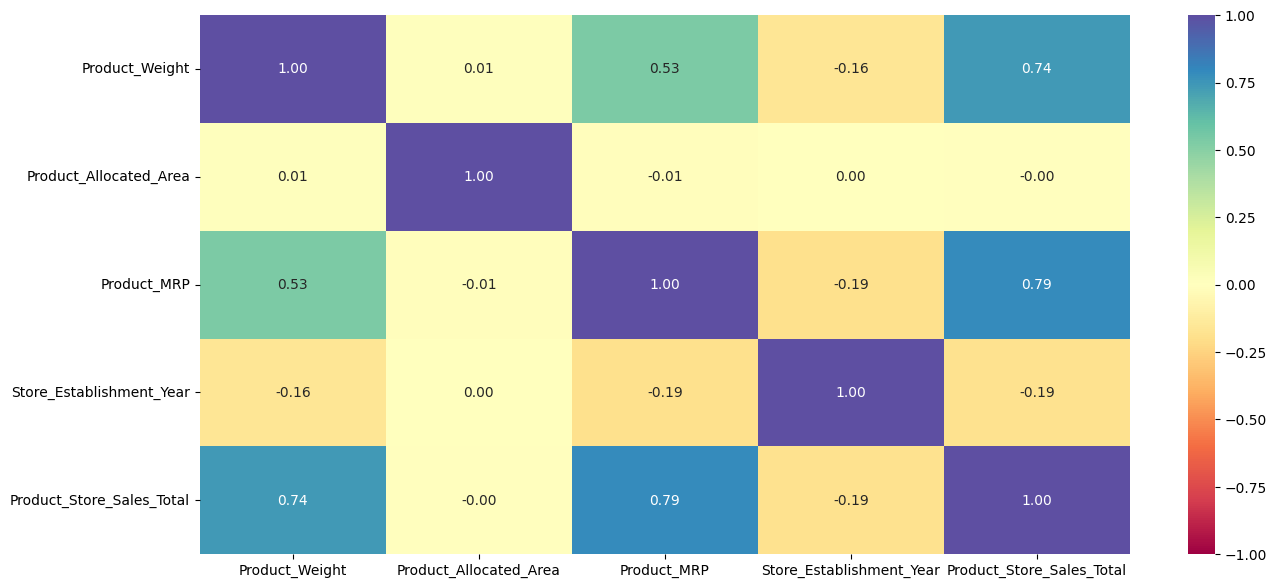

In [39]:
# Let's check the correlation between numerical columns
plt.figure(figsize=(15, 7))
sns.heatmap(dataset.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

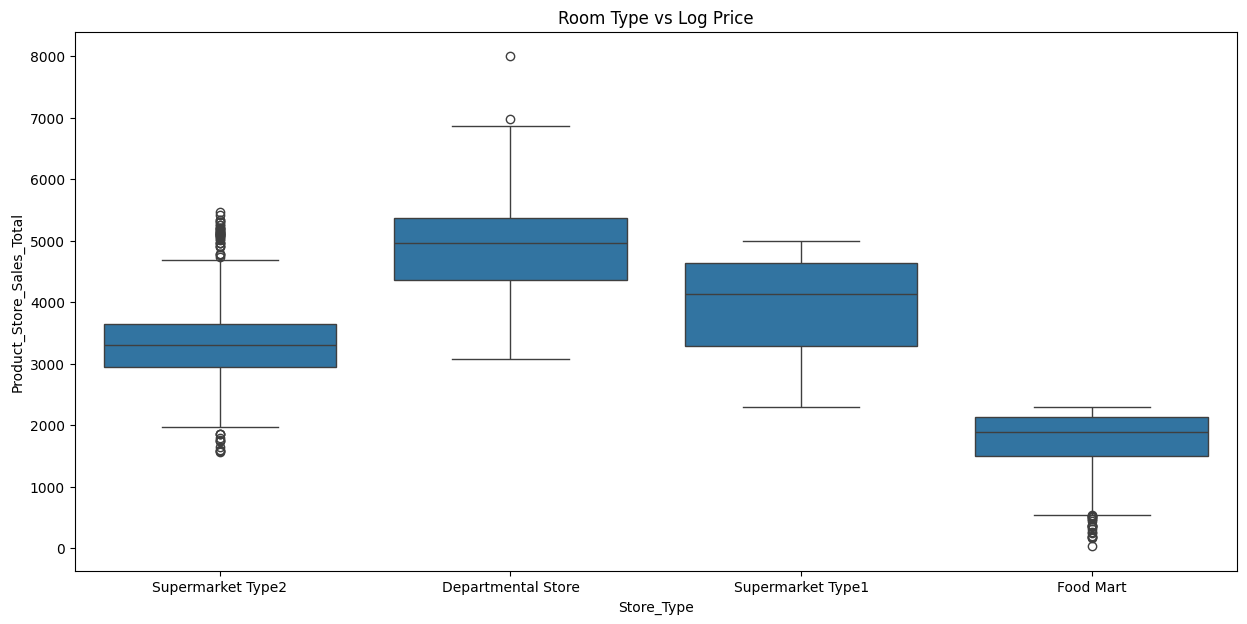

In [43]:
# Store_Type vs Product_Store_Sales_Total
plt.figure(figsize=(15, 7))
sns.boxplot(x="Store_Type", y="Product_Store_Sales_Total", data=dataset)
plt.title("Room Type vs Log Price")
plt.show()

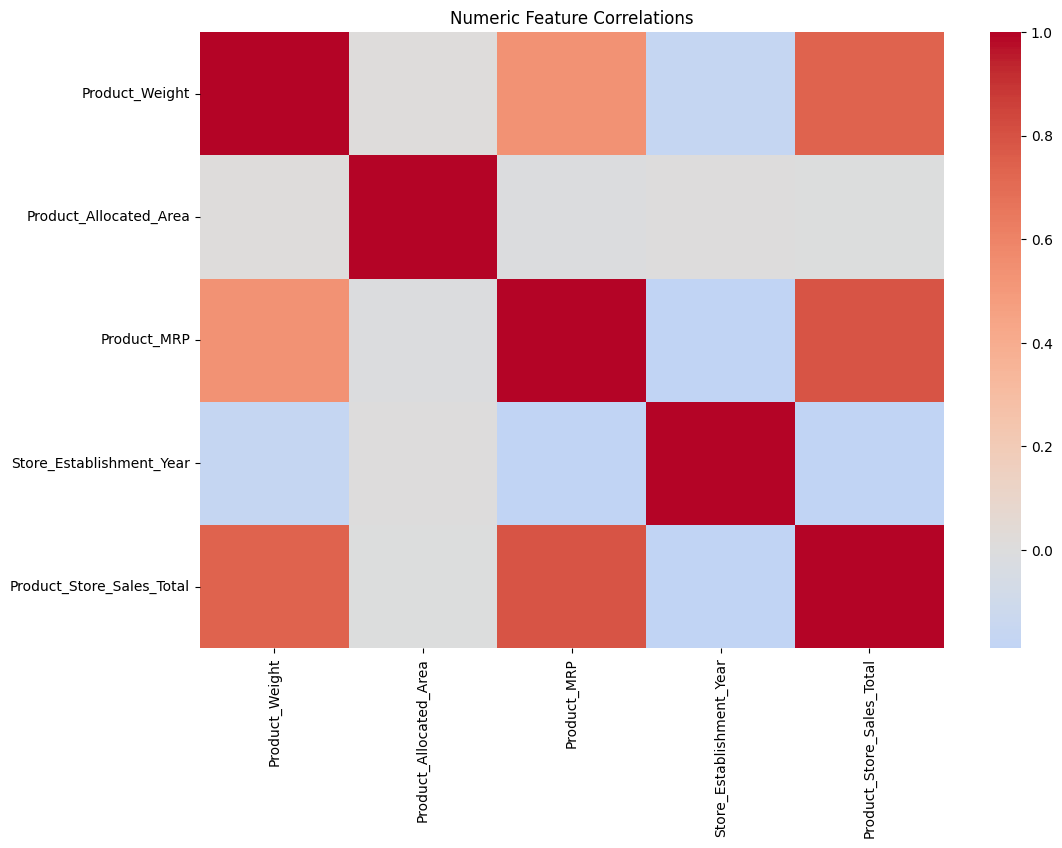

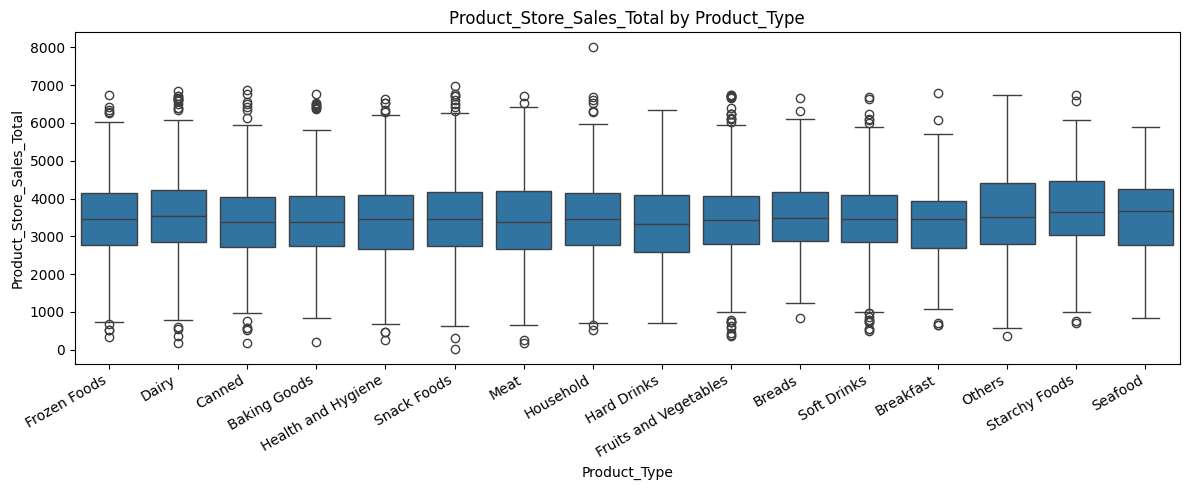

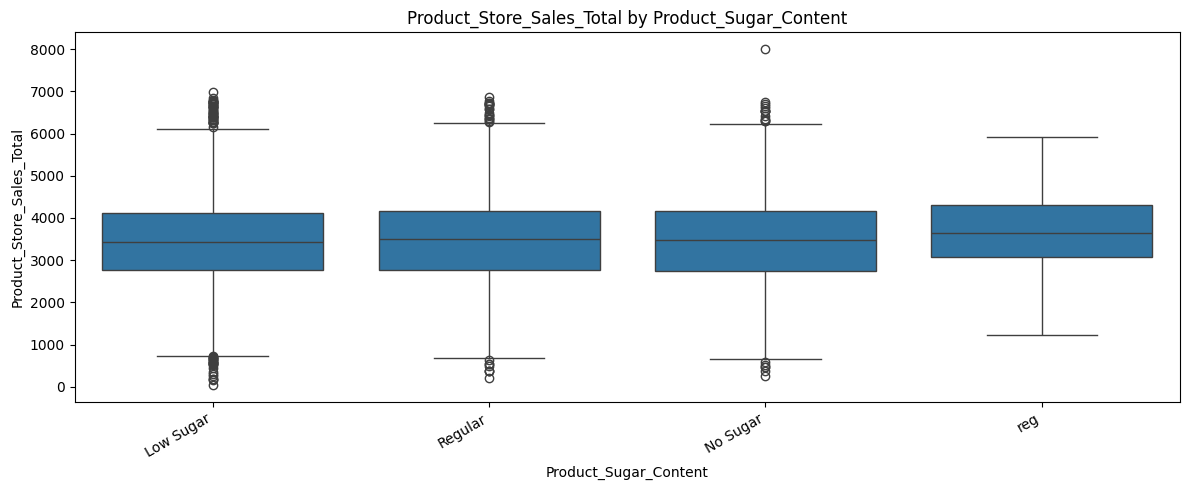

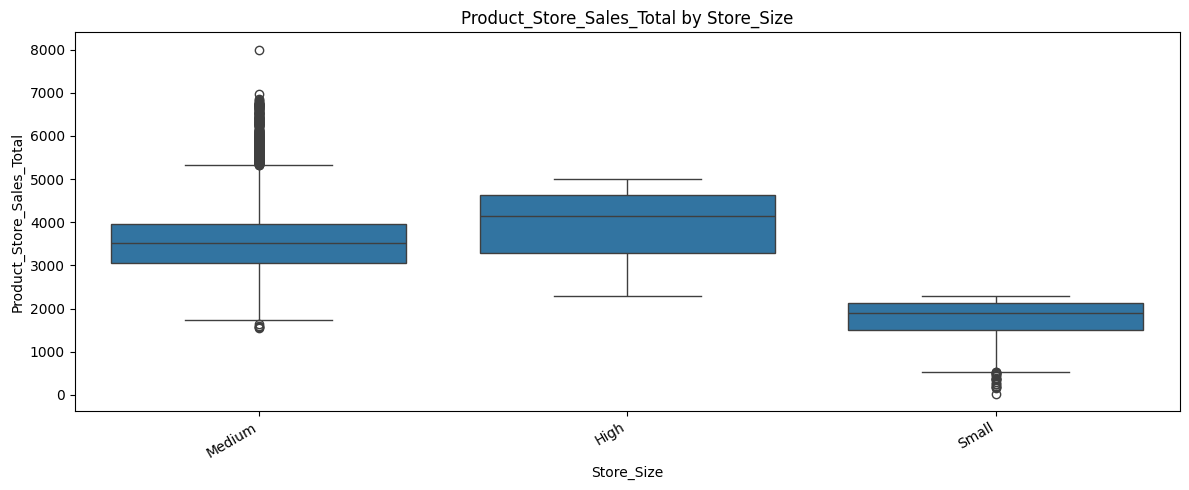

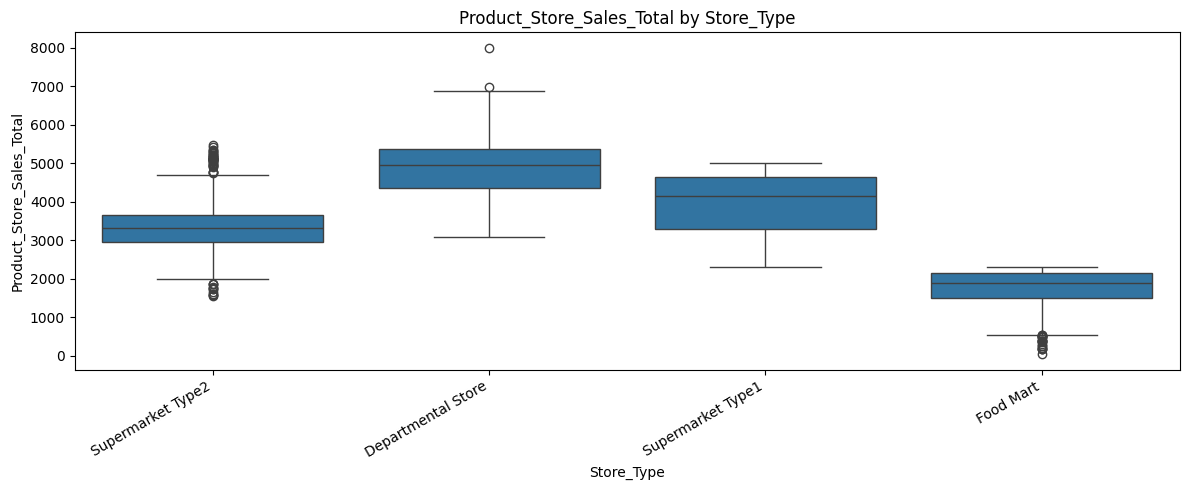

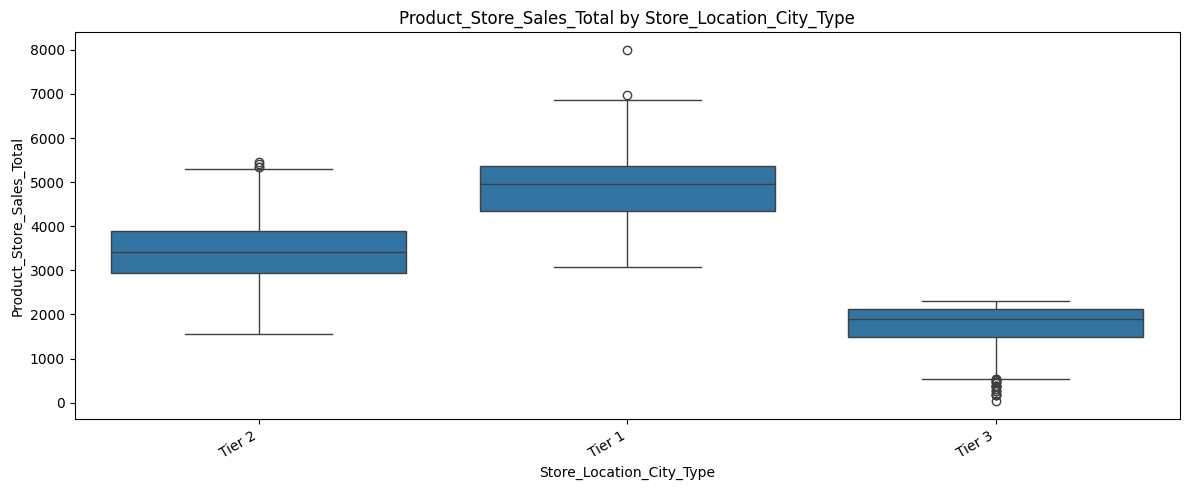

In [40]:
# Bivariate overview: numeric correlations and sales by selected categories
numeric_for_plot = dataset.select_dtypes(include=np.number)
if numeric_for_plot.shape[1] > 1:
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_for_plot.corr(), cmap="coolwarm", center=0)
    plt.title("Numeric Feature Correlations")
    plt.show()

for col in ["Product_Type", "Product_Sugar_Content", "Store_Size", "Store_Type", "Store_Location_City_Type"]:
    if col in dataset.columns:
        plt.figure(figsize=(12, 5))
        sns.boxplot(data=dataset, x=col, y=target)
        plt.xticks(rotation=30, ha="right")
        plt.title(f"{target} by {col}")
        plt.tight_layout()
        plt.show()

# **Data Preprocessing**

In [44]:
# Define predictor matrix (X) using selected numeric and categorical features
X = dataset[numeric_features + categorical_features]

# Define target variable
y = dataset[target]

In [45]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,              # Predictors (X) and target variable (y)
    test_size=0.2,     # 20% of the data is reserved for testing
    random_state=42    # Ensures reproducibility by setting a fixed random seed
)

In [46]:
# Create a preprocessing pipeline for numerical and categorical features

preprocessor = make_column_transformer(
    (Pipeline([('num_imputer', SimpleImputer(strategy='median')),
               ('scaler', StandardScaler())]), numeric_features),
    (Pipeline([('cat_imputer', SimpleImputer(strategy='most_frequent')),
               ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
)

In [51]:
from sklearn.compose import ColumnTransformer

# Define the missing RANDOM_STATE constant for reproducibility
RANDOM_STATE = 42

# Prepare features and target; exclude rows without a known target.
model_data = dataset.dropna(subset=[target]).copy()
X = model_data.drop(columns=[target])
y = model_data[target]

# Treat identifier columns as categorical rather than numeric measurements.
for col in ["Product_Id", "Store_Id"]:
    if col in X.columns:
        X[col] = X[col].astype("string")

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")

Numeric features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year']
Categorical features: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']
Train rows: 7,010; test rows: 1,753


# Model Building

The pipeline below reuses the Airbnb notebook's preprocessing pattern: imputers, scaling for numeric columns, one-hot encoding for categorical columns, train/test split, regression metrics, hyperparameter search, and serialization. The target and feature columns are adapted to SuperKart sales.

Data Preprocessing Pipeline

In [54]:
# Define predictor matrix (X) using selected numeric and categorical features
X = dataset[numeric_features + categorical_features]

# Define target variable
y = dataset[target]

In [55]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,              # Predictors (X) and target variable (y)
    test_size=0.2,     # 20% of the data is reserved for testing
    random_state=42    # Ensures reproducibility by setting a fixed random seed
)

In [56]:
# Create a preprocessing pipeline for numerical and categorical features

preprocessor = make_column_transformer(
    (Pipeline([('num_imputer', SimpleImputer(strategy='median')),
               ('scaler', StandardScaler())]), numeric_features),
    (Pipeline([('cat_imputer', SimpleImputer(strategy='most_frequent')),
               ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
)

Utility Functions

In [57]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

### Random Forest Regressor - Model Training Pipeline#

In [58]:
# Define base Random Forest model
rf_model = RandomForestRegressor(random_state=42)

In [59]:
# Create pipeline with preprocessing and Random Forest model
rf_pipeline = make_pipeline(preprocessor, rf_model)

In [60]:
# Train the model pipeline on the training data
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Establishment_Year']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Id',
                                                   'Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [61]:
rf_estimator_model_train_perf = model_performance_regression(rf_pipeline, X_train,y_train)
print("Training performance \n")
rf_estimator_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,103.018239,28.145401,0.990642,0.990627,0.011663


In [62]:
rf_estimator_model_test_perf = model_performance_regression(rf_pipeline, X_test,y_test)
print("Testing performance \n")
rf_estimator_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,280.513973,77.702408,0.931037,0.930601,0.02952


## Define functions for Model Evaluation

In [52]:
def adj_r2_score(predictors, targets, predictions):
    """Adjusted R-squared using the number of input columns as a simple approximation."""
    r2 = r2_score(targets, predictions)
    n, k = predictors.shape
    if n <= k + 1:
        return np.nan
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


def model_performance_regression(model, predictors, target):
    """Return standard regression metrics for a fitted estimator or pipeline."""
    predictions = model.predict(predictors)
    return pd.DataFrame([{
        "RMSE": float(np.sqrt(mean_squared_error(target, predictions))),
        "MAE": float(mean_absolute_error(target, predictions)),
        "R-squared": float(r2_score(target, predictions)),
        "Adj. R-squared": float(adj_r2_score(predictors, target, predictions)),
        "MAPE": float(mean_absolute_percentage_error(target, predictions)),
    }])

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

In [53]:
# Train two regression pipelines using the shared preprocessing steps.
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        objective="reg:squarederror", random_state=RANDOM_STATE,
        n_jobs=-1
    ),
}

fitted_models = {}
performance_rows = []
for model_name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    fitted_models[model_name] = pipeline
    train_metrics = model_performance_regression(pipeline, X_train, y_train)
    test_metrics = model_performance_regression(pipeline, X_test, y_test)
    performance_rows.append({"Model": model_name, "Split": "Train", **train_metrics.iloc[0].to_dict()})
    performance_rows.append({"Model": model_name, "Split": "Test", **test_metrics.iloc[0].to_dict()})

baseline_results = pd.DataFrame(performance_rows)
display(baseline_results)

,Model,Split,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,Random Forest,Train,103.092722,27.722578,0.990628,0.990613,0.011553
1,Random Forest,Test,280.510908,77.281037,0.931039,0.930603,0.029380
2,XGBoost,Train,198.282897,98.208723,0.965331,0.965276,0.039142
3,XGBoost,Test,294.485772,124.836107,0.923996,0.923516,0.046806


# **Model Performance Improvement - Hyperparameter Tuning**

In [ ]:
# Tune the model with the best baseline test R-squared.
baseline_test = baseline_results[baseline_results["Split"] == "Test"].set_index("Model")
best_baseline_name = baseline_test["R-squared"].idxmax()
print("Best baseline model:", best_baseline_name)

if best_baseline_name == "Random Forest":
    tuned_estimator = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
    param_grid = {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 15, 25],
        "model__min_samples_leaf": [1, 2, 4],
    }
else:
    tuned_estimator = XGBRegressor(
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1
    )
    param_grid = {
        "model__n_estimators": [200, 400],
        "model__max_depth": [3, 5, 7],
        "model__learning_rate": [0.03, 0.07, 0.1],
        "model__subsample": [0.8, 1.0],
    }

tuning_pipeline = Pipeline([("preprocessor", preprocessor), ("model", tuned_estimator)])
grid_search = GridSearchCV(
    tuning_pipeline, param_grid=param_grid, scoring="r2",
    cv=3, n_jobs=-1, verbose=1, refit=True
)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R-squared:", round(grid_search.best_score_, 4))
display(pd.concat([
    model_performance_regression(best_model, X_train, y_train).assign(Split="Train"),
    model_performance_regression(best_model, X_test, y_test).assign(Split="Test"),
], ignore_index=True))

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [ ]:
# Compare baseline models with the tuned model and serialize the complete preprocessing+model pipeline.
comparison_rows = []
for name, model in fitted_models.items():
    comparison_rows.append({"Model": name, "Split": "Test",
                            **model_performance_regression(model, X_test, y_test).iloc[0].to_dict()})
comparison_rows.append({"Model": f"Tuned {best_baseline_name}", "Split": "Test",
                        **model_performance_regression(best_model, X_test, y_test).iloc[0].to_dict()})
model_comparison = pd.DataFrame(comparison_rows).sort_values("R-squared", ascending=False)
display(model_comparison)

DEPLOYMENT_DIR = Path("deployment_files")
DEPLOYMENT_DIR.mkdir(exist_ok=True)
MODEL_PATH = DEPLOYMENT_DIR / "superkart_sales_pipeline.joblib"
joblib.dump(best_model, MODEL_PATH)
print(f"Saved complete model pipeline to: {MODEL_PATH}")

# Sanity-check loading and prediction on a few held-out rows.
loaded_model = joblib.load(MODEL_PATH)
sample_predictions = pd.DataFrame({
    "Actual_Sales": y_test.iloc[:10].to_numpy(),
    "Predicted_Sales": loaded_model.predict(X_test.iloc[:10]),
})
display(sample_predictions)

# Deployment - Backend

The trained preprocessing-plus-model pipeline is saved as a single joblib artifact and loaded by a Flask API.

## Points to note before executing the below cells
- Create a GitHub account if you don't already have one at [github.com](https://github.com)
- Generate a **Personal Access Token**
  - Make sure the token has **repo** scope (full control of private repositories)
- The serialized ML model file (`superkart_model.joblib`) should already be present in the `backend_files` folder before pushing to GitHub
- We will deploy **both the Flask backend and the Streamlit frontend as separate Docker containers** inside a GitHub Codespace, and connect them using a **Docker network**

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [ ]:
%%writefile deployment_files/api.py
from pathlib import Path
import io
import joblib
import pandas as pd
from flask import Flask, request, jsonify

app = Flask(__name__)
MODEL_PATH = Path(__file__).resolve().parent / "superkart_sales_pipeline.joblib"
model = joblib.load(MODEL_PATH)


@app.get("/health")
def health():
    return jsonify({"status": "ok", "model": "superkart_sales_pipeline"})


@app.post("/v1/predict")
def predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"error": "Send one JSON object containing the feature columns."}), 400
    try:
        features = pd.DataFrame([payload])
        prediction = float(model.predict(features)[0])
        return jsonify({"predicted_sales": prediction})
    except Exception as exc:
        return jsonify({"error": str(exc)}), 400


@app.post("/v1/predictbatch")
def predict_batch():
    uploaded = request.files.get("file")
    if uploaded is None:
        return jsonify({"error": "Upload a CSV using the 'file' form field."}), 400
    try:
        data = pd.read_csv(uploaded)
        predictions = model.predict(data)
        result = data.copy()
        result["Predicted_Product_Store_Sales_Total"] = predictions
        return result.to_json(orient="records")
    except Exception as exc:
        return jsonify({"error": str(exc)}), 400


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=7860, debug=False)

## Dependencies File

In [ ]:
%%writefile deployment_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
Flask==3.1.0
streamlit==1.43.2
requests==2.32.4
PyGithub==2.6.1

## Dockerfile

In [ ]:
%%writefile deployment_files/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 7860
CMD ["python", "api.py"]

# Deployment - Frontend

The Streamlit interface loads the same serialized pipeline and supports single-row and CSV batch predictions.

## Streamlit for Interactive UI

In [ ]:
%%writefile deployment_files/app.py
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

MODEL_PATH = Path(__file__).resolve().parent / "superkart_sales_pipeline.joblib"

st.set_page_config(page_title="SuperKart Sales Predictor", page_icon="🛒")
st.title("🛒 SuperKart Sales Predictor")
st.write("Enter the product and store attributes to estimate total sales.")

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

model = load_model()

st.subheader("Single prediction")
with st.form("prediction_form"):
    product_weight = st.number_input("Product Weight", min_value=0.0, value=12.0)
    sugar = st.selectbox("Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"])
    allocated_area = st.number_input("Product Allocated Area", min_value=0.0, value=0.05)
    mrp = st.number_input("Product MRP", min_value=0.0, value=150.0)
    product_type = st.text_input("Product Type", "Snack Foods")
    product_id = st.text_input("Product ID", "FD1")
    store_id = st.text_input("Store ID", "OUT049")
    establishment_year = st.number_input("Store Establishment Year", min_value=1900, max_value=2100, value=2000)
    store_size = st.selectbox("Store Size", ["Low", "Medium", "High"])
    city_type = st.selectbox("Store Location City Type", ["Tier 1", "Tier 2", "Tier 3"])
    store_type = st.selectbox("Store Type", ["Departmental Store", "Supermarket Type1", "Supermarket Type2", "Food Mart"])
    submitted = st.form_submit_button("Predict sales")

if submitted:
    row = pd.DataFrame([{
        "Product_Weight": product_weight,
        "Product_Sugar_Content": sugar,
        "Product_Allocated_Area": allocated_area,
        "Product_Type": product_type,
        "Product_MRP": mrp,
        "Product_Id": product_id,
        "Store_Id": store_id,
        "Store_Establishment_Year": establishment_year,
        "Store_Size": store_size,
        "Store_Location_City_Type": city_type,
        "Store_Type": store_type,
    }])
    try:
        prediction = float(model.predict(row)[0])
        st.success(f"Predicted total sales: {prediction:,.2f}")
    except Exception as exc:
        st.error(f"Prediction failed. Check that the input fields match the training dataset. Details: {exc}")

st.subheader("Batch predictions")
uploaded = st.file_uploader("Upload a CSV containing the model feature columns", type=["csv"])
if uploaded is not None:
    batch = pd.read_csv(uploaded)
    st.write("Input preview", batch.head())
    if st.button("Predict batch"):
        try:
            batch["Predicted_Product_Store_Sales_Total"] = model.predict(batch)
            st.dataframe(batch)
            st.download_button("Download predictions", batch.to_csv(index=False), "superkart_predictions.csv", "text/csv")
        except Exception as exc:
            st.error(f"Batch prediction failed. Ensure the CSV has the same feature columns as the training data. Details: {exc}")

## Dependencies File

In [ ]:
%%writefile deployment_files/requirements-streamlit.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
streamlit==1.43.2

%%writefile deployment_files/Dockerfile.streamlit
FROM python:3.11-slim
WORKDIR /app
COPY requirements-streamlit.txt requirements.txt
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 8501
CMD ["streamlit", "run", "app.py", "--server.address=0.0.0.0", "--server.port=8501"]

# **Pushing Deployment Files to GitHub**

In [ ]:
# Optional: publish deployment files to a new GitHub repository from Google Colab.
# Before running, add a Colab secret named GITHUB_TOKEN containing a fine-grained
# or classic personal access token with permission to create/push repository contents.
# Review the files and choose a repository name before publishing.
from pathlib import Path

REPO_NAME = "superkart-sales-prediction"
MAKE_PUBLIC = True  # Change to False if you want a private repository.

try:
    from google.colab import userdata
    from github import Github

    github_token = userdata.get("GITHUB_TOKEN")
    if not github_token:
        raise ValueError("Add your token in Colab Secrets as GITHUB_TOKEN.")

    github_client = Github(github_token)
    github_user = github_client.get_user()
    repo = github_user.create_repo(
        REPO_NAME,
        private=not MAKE_PUBLIC,
        description="SuperKart product-store sales prediction API and Streamlit app",
        auto_init=True,
    )

    deployment_dir = Path("deployment_files")
    for path in deployment_dir.iterdir():
        if path.is_file():
            content = path.read_bytes()
            try:
                existing = repo.get_contents(path.name)
                repo.update_file(path.name, f"Add/update {path.name}", content, existing.sha)
            except Exception:
                repo.create_file(path.name, f"Add {path.name}", content)

    print(f"Deployment files pushed to: {repo.html_url}")
except ImportError:
    print("Install PyGithub and run this cell in Google Colab to publish files.")
except Exception as exc:
    print(f"GitHub publishing did not complete: {exc}")

# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [ ]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [ ]:
model_root_url = "_____"  # Complete the code to replace with your Codespace forwarded URL for port 7860

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [ ]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [ ]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [ ]:
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [ ]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [ ]:
response

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [ ]:
print(response.json())

`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [ ]:
batch_dataset = pd.read_csv("Batch_Data_SuperKart.csv")

**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [ ]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [ ]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [ ]:
response

In [ ]:
# Extract predictions from API response
response.text

As we can see, we receive a JSON where each key represents a row index, and the value represents the model's predicted sales for that product.

# **Actionable Insights and Business Recommendations**

-

-